# House Price Prediction - Linear Regression

This notebook trains a Linear Regression model to predict the dataset's observed `price` column. It reuses the cleaning rules and numeric/categorical preprocessing from `data_preprocessing.ipynb`. Learned preprocessing steps are fitted on training data only, and the original CSV is never changed.

## 1. Load and inspect the dataset

The source file is loaded with a path relative to this notebook. The target column is `price`, as confirmed by inspecting the dataset columns.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

data_path = Path("../dataset/Housing.csv")
raw_houses = pd.read_csv(data_path)

print(f"Loaded: {data_path.name}")
print("Dataset shape:", raw_houses.shape)
print("Actual columns:", raw_houses.columns.tolist())
raw_houses.head()

Loaded: Housing.csv
Dataset shape: (545, 13)
Actual columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 2. Apply the same careful cleaning rules

As in the preprocessing notebook, remove exact duplicate rows and rows without a target only if they exist. Normalize surrounding spaces and letter case in categorical values. Remove rows only when a positive-valued field (`price`, `area`, `bedrooms`, `bathrooms`, or `stories`) is nonpositive, or parking is negative; zero parking spaces is valid. Unexpected category labels stop execution for review instead of being silently changed.

In [2]:
target_column = "price"
if target_column not in raw_houses.columns:
    raise KeyError(f"Target column {target_column!r} was not found. Review the dataset columns.")

houses = raw_houses.copy()

duplicate_rows_removed = int(houses.duplicated().sum())
houses = houses.drop_duplicates().copy()

missing_target_rows_removed = int(houses[target_column].isna().sum())
houses = houses.dropna(subset=[target_column]).copy()

categorical_columns = houses.select_dtypes(include=["object", "category", "string"]).columns.tolist()
normalized_category_values = 0
for column in categorical_columns:
    original_values = houses[column].astype("string")
    cleaned_values = original_values.str.strip().str.lower()
    normalized_category_values += int((original_values.notna() & original_values.ne(cleaned_values)).sum())
    houses[column] = cleaned_values

expected_categories = {
    "mainroad": {"yes", "no"},
    "guestroom": {"yes", "no"},
    "basement": {"yes", "no"},
    "hotwaterheating": {"yes", "no"},
    "airconditioning": {"yes", "no"},
    "prefarea": {"yes", "no"},
    "furnishingstatus": {"furnished", "semi-furnished", "unfurnished"},
}
unexpected_categories = {}
for column, allowed_values in expected_categories.items():
    if column in houses.columns:
        observed_values = set(houses[column].dropna().unique())
        unexpected_values = observed_values - allowed_values
        if unexpected_values:
            unexpected_categories[column] = sorted(unexpected_values)
if unexpected_categories:
    raise ValueError(f"Review unexpected categorical values before continuing: {unexpected_categories}")

positive_columns = [
    column for column in ["price", "area", "bedrooms", "bathrooms", "stories"]
    if column in houses.columns
]
invalid_numeric_rows = pd.Series(False, index=houses.index)
for column in positive_columns:
    invalid_numeric_rows |= houses[column].notna() & houses[column].le(0)
if "parking" in houses.columns:
    invalid_numeric_rows |= houses["parking"].notna() & houses["parking"].lt(0)

invalid_numeric_rows_removed = int(invalid_numeric_rows.sum())
houses = houses.loc[~invalid_numeric_rows].copy()

print("Duplicate rows removed:", duplicate_rows_removed)
print("Rows removed because price was missing:", missing_target_rows_removed)
print("Rows removed for invalid numeric values:", invalid_numeric_rows_removed)
print("Category values normalized:", normalized_category_values)
print("Rows available for modeling:", len(houses))

Duplicate rows removed: 0
Rows removed because price was missing: 0
Rows removed for invalid numeric values: 0
Category values normalized: 0
Rows available for modeling: 545


## 3. Separate features and target, then split

`price` is the target (`y`); all other dataset columns are retained as input features (`X`). The test set is held out before fitting the preprocessing steps or model. The fixed random state makes the 80/20 split reproducible.

In [3]:
X = houses.drop(columns=[target_column]).copy()
y = houses[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print("Target column:", target_column)
print("Input features retained:", X.columns.tolist())
print("Number of training records:", len(X_train))
print("Number of testing records:", len(X_test))

Target column: price
Input features retained: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Number of training records: 436
Number of testing records: 109


## 4. Build one pipeline for preprocessing and Linear Regression

Numeric feature gaps are filled with the training median. Categorical gaps are filled with the most frequent training value and then one-hot encoded. The `ColumnTransformer` applies these steps by column type. The final `Pipeline` joins preprocessing to `LinearRegression`, so training and future predictions use the same transformations. Unknown categories are ignored safely.

In [4]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()
unassigned_features = set(X_train.columns) - set(numeric_features) - set(categorical_features)
if unassigned_features:
    raise TypeError(f"Review feature columns with unsupported data types: {sorted(unassigned_features)}")

numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    sparse_threshold=0.0,
)
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("linear_regression", LinearRegression()),
    ]
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


## 5. Train and generate test predictions

Calling `fit` with `X_train` and `y_train` learns both the transformations and Linear Regression coefficients from training data only. Then `predict` generates prices for the held-out test features; test targets are used only for the requested actual-versus-predicted display and plot.

In [5]:
model_pipeline.fit(X_train, y_train)
predicted_prices = model_pipeline.predict(X_test)

print("Number of training records:", len(X_train))
print("Number of testing records:", len(X_test))
print("Predictions generated for held-out test records:", len(predicted_prices))

Number of training records: 436
Number of testing records: 109
Predictions generated for held-out test records: 109


## 6. Review coefficients, intercept, and sample predictions

Each coefficient corresponds to a transformed feature, including the one-hot encoded categories. The intercept is the model's estimated baseline. The table shows the first ten held-out actual prices beside their predictions; no evaluation metrics are calculated in this step.

In [6]:
linear_regression = model_pipeline.named_steps["linear_regression"]
transformed_feature_names = model_pipeline.named_steps["preprocessor"].get_feature_names_out()

coefficients = pd.DataFrame(
    {
        "feature": transformed_feature_names,
        "coefficient": linear_regression.coef_,
    }
).sort_values(by="coefficient", ascending=False)

print("Model intercept:", f"{linear_regression.intercept_:,.2f}")
print("Model coefficients:")
display(coefficients.reset_index(drop=True))

actual_vs_predicted = pd.DataFrame(
    {
        "actual_price": y_test.to_numpy(),
        "predicted_price": predicted_prices,
    },
    index=y_test.index,
)
print("First 10 actual vs predicted prices:")
display(actual_vs_predicted.head(10).round(2))

Model intercept: 1,627,730.90
Model coefficients:


,feature,coefficient
0,numeric__bathrooms,1.094445e+06
1,numeric__stories,4.074766e+05
2,categorical__airconditioning_yes,3.957134e+05
3,categorical__hotwaterheating_yes,3.423249e+05
4,categorical__prefarea_yes,3.149453e+05
5,numeric__parking,2.248419e+05
6,categorical__basement_yes,1.951256e+05
7,categorical__mainroad_yes,1.839600e+05
8,categorical__furnishingstatus_furnished,1.801756e+05
9,categorical__guestroom_yes,1.158050e+05


First 10 actual vs predicted prices:


,actual_price,predicted_price
316,4060000,5164653.90
77,6650000,7224722.30
360,3710000,3109863.24
90,6440000,4612075.33
493,2800000,3294646.26
209,4900000,3532275.10
176,5250000,5611774.57
249,4543000,6368145.99
516,2450000,2722856.96
426,3353000,2629405.62


## 7. Compare actual and predicted prices

Each point compares one test-set prediction with its actual price. The dashed diagonal marks perfect agreement; points closer to it have predictions closer to the observed values. This is a visualization only, not a calculation of evaluation metrics.

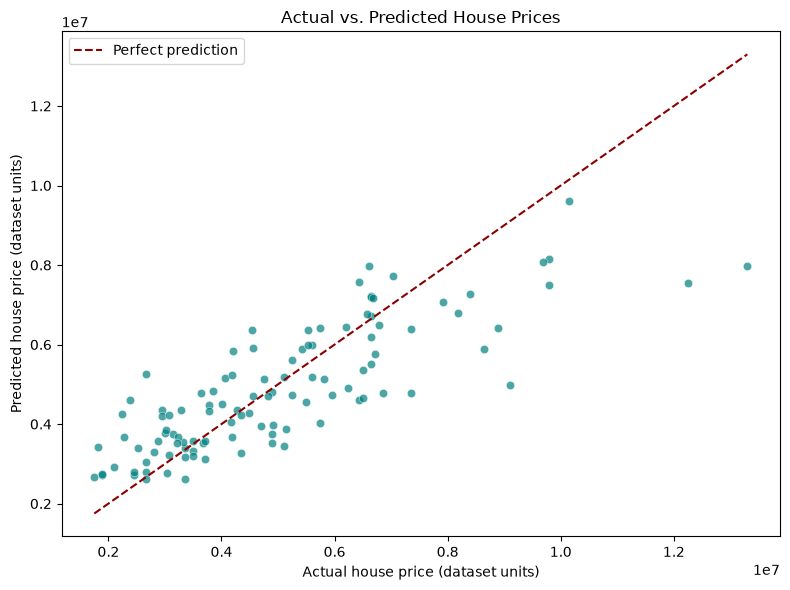

Saved comparison plot: ..\outputs\visualizations\actual_vs_predicted_house_prices.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, predicted_prices, alpha=0.7, color="teal", edgecolor="white", linewidth=0.4)

plot_min = min(float(y_test.min()), float(predicted_prices.min()))
plot_max = max(float(y_test.max()), float(predicted_prices.max()))
ax.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--", color="darkred", label="Perfect prediction")
ax.set_title("Actual vs. Predicted House Prices")
ax.set_xlabel("Actual house price (dataset units)")
ax.set_ylabel("Predicted house price (dataset units)")
ax.legend()
fig.tight_layout()

visualization_dir = Path("../outputs/visualizations")
visualization_dir.mkdir(parents=True, exist_ok=True)
comparison_plot_path = visualization_dir / "actual_vs_predicted_house_prices.png"
fig.savefig(comparison_plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved comparison plot:", comparison_plot_path)

## 8. Save and reload the complete pipeline

Save the fitted preprocessing-plus-regression pipeline with `joblib`. Reload it and predict the same held-out inputs to confirm that the saved file works and reproduces the in-memory pipeline's predictions.

In [8]:
model_path = Path("../model/house_price_model.pkl")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model_pipeline, model_path)

loaded_model_pipeline = joblib.load(model_path)
reloaded_predictions = loaded_model_pipeline.predict(X_test)
np.testing.assert_allclose(reloaded_predictions, predicted_prices)

print("Saved pipeline:", model_path)
print("File size:", f"{model_path.stat().st_size:,} bytes")
print("Joblib reload and prediction check: successful")
print("The saved pipeline includes both preprocessing and Linear Regression.")

Saved pipeline: ..\model\house_price_model.pkl
File size: 5,346 bytes
Joblib reload and prediction check: successful
The saved pipeline includes both preprocessing and Linear Regression.


## Model development complete

The pipeline was trained using the 80% training split and used to predict the 20% held-out split. Preprocessing was fitted only on training data. No evaluation metrics have been added; those belong to the next step.